# Lab 3 적용 — 특성 선택과 리샘플링 (Give Me Some Credit)

**Lab 2에서 넘어온 질문:** 변수 8개가 다 필요할까? 그리고 지금 하는 평가는 믿을 만할까?

Lab 3의 순서를 그대로 따른다.
1. 특성 선택: 단변량 통계 검정(SelectKBest·chi2) → RFE → PCA → ExtraTrees 중요도
2. 리샘플링: train/test 분할 → k-fold 교차검증 → LOOCV → 반복 무작위 분할(ShuffleSplit)

Lab 3은 로지스틱 회귀를 기준 모델로 쓴다. Lab 2의 결론대로 **로그+표준화 데이터**를 기본으로 하고,
원본 데이터 결과는 비교용으로 함께 본다. 평가는 정확도와 AUC를 같이 본다.

In [1]:
import glob, os, time
import numpy
from pandas import read_csv, DataFrame
from matplotlib import pyplot, font_manager
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

for p in glob.glob(os.path.expandvars(r'%LOCALAPPDATA%\Microsoft\Windows\Fonts\Pretendard-*.ttf')):
    font_manager.fontManager.addfont(p)
pyplot.rcParams['font.family'] = 'Pretendard'
pyplot.rcParams['axes.unicode_minus'] = False
BLUE, RED, GRAY, VIOLET, INK = '#3182F6', '#F04452', '#B0B8C1', '#7C5CFF', '#191F28'
numpy.set_printoptions(precision=3, suppress=True)

filename = '../data/givemesomecredit.csv'
names = ['target', 'revol', 'age', 'late30', 'debt', 'income', 'depend', 'defaulted', 'loans']
features = names[1:]
dataframe = read_csv(filename, names=names, header=0)
array = dataframe.values
X = array[:, 1:9].astype(float)
Y = array[:, 0].astype(int)

# Lab 2 결론: 치우친 4개 열은 log1p, 그다음 표준화
Xlog = X.copy()
for c in ['revol', 'late30', 'debt', 'income']:
    Xlog[:, features.index(c)] = numpy.log1p(Xlog[:, features.index(c)])
Xs = StandardScaler().fit_transform(Xlog)
print(X.shape, Xs.shape)

(150000, 8) (150000, 8)


## 1. 특성 선택
### 1-1. 단변량 통계 검정 (Lab 3: `SelectKBest(score_func=chi2, k=4)`)

In [2]:
from sklearn.feature_selection import SelectKBest, chi2
# chi2는 음수가 없는 값이 필요하다 → 원본(X)과 로그 변환(Xlog) 모두 음수 없음
for label, XX in [('원본', X), ('로그 변환', Xlog)]:
    test = SelectKBest(score_func=chi2, k=4)
    fit = test.fit(XX, Y)
    order = numpy.argsort(-fit.scores_)
    print(f'[{label}] 점수:', fit.scores_.round(0))
    print(f'[{label}] 상위 4개:', [features[i] for i in order[:4]])

[원본] 점수: [   5020.    8334.   98779.  101978. 1223268.     548.   11826.     116.]
[원본] 상위 4개: ['income', 'debt', 'late30', 'defaulted']
[로그 변환] 점수: [ 2753.  8334. 12136.   201.     9.   548. 11826.   116.]
[로그 변환] 상위 4개: ['late30', 'defaulted', 'age', 'revol']


**(a) 가장 점수가 높은 4개:** 원본은 income, debt, late30, defaulted. 그런데 income이 1위인 이유는 **값이 커서**다.
카이제곱 점수는 값의 크기에 비례해 커지기 때문이다. 로그 변환 후에는 late30, defaulted, age, revol이 상위 4개다.

### 1-2. RFE: 재귀적 특성 제거 (Lab 3: `RFE(model, 3)` → 최신 버전은 `n_features_to_select=3`)

In [3]:
from sklearn.feature_selection import RFE
for label, XX in [('원본', X), ('로그+표준화', Xs)]:
    model = LogisticRegression(solver='liblinear')
    rfe = RFE(model, n_features_to_select=3)
    fit = rfe.fit(XX, Y)
    print(f'[{label}] 선택:', [features[i] for i in numpy.where(fit.support_)[0]])
    print(f'[{label}] 순위:', dict(zip(features, fit.ranking_.tolist())))

[원본] 선택: ['depend', 'defaulted', 'loans']
[원본] 순위: {'revol': 4, 'age': 2, 'late30': 3, 'debt': 6, 'income': 5, 'depend': 1, 'defaulted': 1, 'loans': 1}


[로그+표준화] 선택: ['revol', 'age', 'defaulted']
[로그+표준화] 순위: {'revol': 1, 'age': 1, 'late30': 2, 'debt': 6, 'income': 5, 'depend': 4, 'defaulted': 1, 'loans': 3}


**(b)(c) RFE가 고른 3개:** 로그+표준화 데이터에서는 revol, age, defaulted (순위 1).
원본 데이터에서는 depend, defaulted, loans가 뽑혔다. 회귀 계수는 열의 단위에 따라 크기가 달라져서, 단위를 맞추지 않으면 RFE도 왜곡된다.

### 1-3. PCA: 주성분 분석 (Lab 3: `PCA(n_components=3)`)

In [4]:
from sklearn.decomposition import PCA
for label, XX in [('원본', X), ('로그+표준화', Xs)]:
    pca = PCA(n_components=3)
    fit = pca.fit(XX)
    print(f'[{label}] 설명된 분산 비율:', fit.explained_variance_ratio_.round(3),
          ' 성분별 가장 큰 변수:', [features[numpy.argmax(abs(c))] for c in fit.components_])

[원본] 설명된 분산 비율: [0.975 0.024 0.   ]  성분별 가장 큰 변수: ['income', 'debt', 'revol']
[로그+표준화] 설명된 분산 비율: [0.24  0.161 0.157]  성분별 가장 큰 변수: ['defaulted', 'income', 'age']


원본에서는 첫 번째 성분이 분산의 97.5%를 설명하는데, 거의 income 하나다(값이 가장 커서).
로그+표준화 후에는 24%, 16%, 16%로 고르게 나뉜다 → 한 변수가 정보를 독점하지 않는다.

**(d) PCA가 유용한 실제 예:** ① 얼굴 사진 인식(수만 개 픽셀을 수십 개 성분으로 압축), ② 유전자 발현 분석(변수 수천 개를 소수 성분으로 요약해 시각화),
③ 설문·금융 지표 압축(서로 겹치는 지표를 묶어 소수 요인으로). 공통점은 변수가 매우 많고 서로 겹치는 정보가 많다는 것이다.
이 데이터는 변수가 8개뿐이고 서로 상관도 낮아(최대 0.22) PCA의 이득이 작다.

### 1-4. 특성 중요도 (Lab 3: `ExtraTreesClassifier`)

In [5]:
from sklearn.ensemble import ExtraTreesClassifier
model = ExtraTreesClassifier(n_estimators=100, random_state=7, n_jobs=-1)
model.fit(X, Y)
importance = DataFrame({'중요도': model.feature_importances_}, index=features).sort_values('중요도', ascending=False)
print(importance.round(3))

             중요도
debt       0.255
revol      0.250
income     0.203
age        0.123
defaulted  0.093
late30     0.044
depend     0.025
loans      0.006


**(e) 중요도 계산 방식:** 트리가 나눌 때마다 불순도(지니 지수)가 얼마나 줄었는지를 변수별로 더하고, 100개 트리에서 평균한 값이다.
값의 범위가 넓은 변수(debt, revol, income)는 나눌 지점이 많아 중요도가 높게 나오는 경향이 있다.

**(f) 기준 점수 정하기:** 정해진 값은 없다. 중요도가 큰 순서로 변수를 하나씩 더해 가며 교차검증 성능이 더 오르지 않는 지점을 기준으로 삼는다 → 아래에서 실제로 확인한다.

### 1-5. 네 방법 비교와 '정말 줄여야 하나' 확인

In [6]:
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=7)
lr = LogisticRegression(solver='liblinear')
def auc_of(cols, XX=Xs):
    idx = [features.index(c) for c in cols]
    s = cross_val_score(lr, XX[:, idx], Y, cv=skf, scoring='roc_auc')
    return s.mean(), s.std()

ranked = importance.index.tolist()
rows = []
for k in [3, 4, 5, 6, 7, 8]:
    m, sd = auc_of(ranked[:k])
    rows.append((f'상위 {k}개', m, sd))
    print(f'중요도 상위 {k}개 {ranked[:k]} → AUC {m:.4f} ({sd:.4f})')
from sklearn.pipeline import Pipeline
s = cross_val_score(Pipeline([('pca', PCA(n_components=3)), ('lr', lr)]), Xs, Y, cv=skf, scoring='roc_auc')
rows.append(('PCA 3성분', s.mean(), s.std()))
print(f'PCA 3성분 → AUC {s.mean():.4f} ({s.std():.4f})')
subset = DataFrame(rows, columns=['구성', 'AUC', 'std'])

중요도 상위 3개 ['debt', 'revol', 'income'] → AUC 0.7777 (0.0056)


중요도 상위 4개 ['debt', 'revol', 'income', 'age'] → AUC 0.7530 (0.0041)


중요도 상위 5개 ['debt', 'revol', 'income', 'age', 'defaulted'] → AUC 0.8253 (0.0086)


중요도 상위 6개 ['debt', 'revol', 'income', 'age', 'defaulted', 'late30'] → AUC 0.8261 (0.0088)


중요도 상위 7개 ['debt', 'revol', 'income', 'age', 'defaulted', 'late30', 'depend'] → AUC 0.8258 (0.0088)


중요도 상위 8개 ['debt', 'revol', 'income', 'age', 'defaulted', 'late30', 'depend', 'loans'] → AUC 0.8240 (0.0088)


PCA 3성분 → AUC 0.8223 (0.0088)


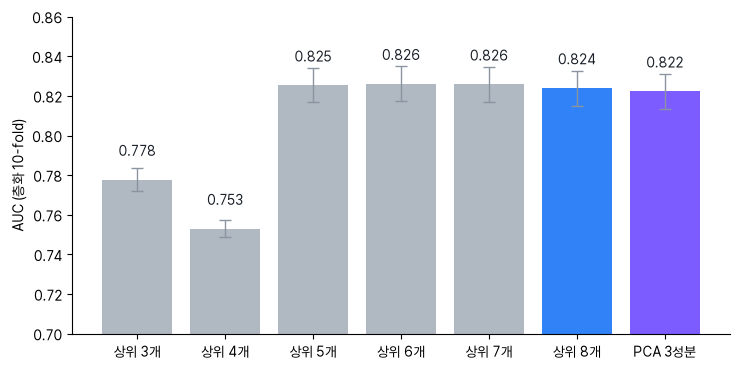

In [7]:
fig, ax = pyplot.subplots(figsize=(7.5, 3.8))
cols = [GRAY] * (len(subset) - 2) + [BLUE, VIOLET]
bars = ax.bar(subset['구성'], subset['AUC'], yerr=subset['std'], color=cols, capsize=4, error_kw={'ecolor': '#8B95A1', 'lw': 1})
for b, v in zip(bars, subset['AUC']):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.012, f'{v:.3f}', ha='center', fontsize=10, color=INK)
ax.set_ylim(0.70, 0.86); ax.set_ylabel('AUC (층화 10-fold)')
ax.spines[['top', 'right']].set_visible(False)
pyplot.tight_layout(); pyplot.savefig('../figures/lab3_subset_auc.png', dpi=200); pyplot.show()

상위 3–4개만 쓰면 0.75–0.78로 떨어진다. 5개부터 0.82대를 회복하고, 6개(0.826)가 8개(0.824)보다 0.002 높다.
하지만 이 차이는 10-fold 표준편차(약 0.007)보다 작다 → **의미 있는 차이가 아니다. 변수 8개를 모두 유지한다.**

## 2. 리샘플링
**(g)** 학습에 쓴 데이터로 평가하면, 데이터를 외운 모델이 만점을 받는다(과적합). 새 데이터에서의 성능을 추정하려면 학습에 안 쓴 데이터로 평가해야 한다.

### 2-1. train/test 분할 (Lab 3: 67% / 33%, seed 7)

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
test_size, seed = 0.33, 7
X_train, X_test, Y_train, Y_test = train_test_split(Xs, Y, test_size=test_size, random_state=seed)
model = LogisticRegression(solver='liblinear')
model.fit(X_train, Y_train)
result = model.score(X_test, Y_test)
print('Accuracy: %.3f%%' % (result * 100.0))
print('AUC     : %.4f' % roc_auc_score(Y_test, model.predict_proba(X_test)[:, 1]))

split_auc = []
for sd in range(10):
    a, b, c, d = train_test_split(Xs, Y, test_size=test_size, random_state=sd)
    m = LogisticRegression(solver='liblinear').fit(a, c)
    split_auc.append(roc_auc_score(d, m.predict_proba(b)[:, 1]))
print('seed 0~9로 나눌 때 AUC:', numpy.round(split_auc, 4), ' 범위', round(min(split_auc), 4), '~', round(max(split_auc), 4))

Accuracy: 93.253%
AUC     : 0.8227


seed 0~9로 나눌 때 AUC: [0.816 0.826 0.823 0.824 0.819 0.825 0.827 0.823 0.828 0.826]  범위 0.8161 ~ 0.8276


**(h)** 정확도 93.25%, AUC 0.823. **(i)** seed를 고정해야 같은 분할이 재현되어 다른 모델과 공정하게 비교할 수 있다. 실제로 seed만 바꿔도 AUC가 0.816~0.828로 움직인다.

### 2-2. k-fold 교차검증 (Lab 3: `KFold(n_splits=10, shuffle=True, random_state=7)`)

In [9]:
num_folds, seed = 10, 7
kfold = KFold(n_splits=num_folds, random_state=seed, shuffle=True)
model = LogisticRegression(solver='liblinear')
acc = cross_val_score(model, Xs, Y, cv=kfold)
auc = cross_val_score(model, Xs, Y, cv=kfold, scoring='roc_auc')
print('Accuracy: %.3f%% (%.3f%%)' % (acc.mean() * 100.0, acc.std() * 100.0))
print('AUC     : %.4f (%.4f)' % (auc.mean(), auc.std()))
print('fold별 연체 비율(KFold)    :', [round(Y[te].mean() * 100, 2) for _, te in kfold.split(Xs)])
print('fold별 연체 비율(Stratified):', [round(Y[te].mean() * 100, 2) for _, te in skf.split(Xs, Y)])
sauc = cross_val_score(model, Xs, Y, cv=skf, scoring='roc_auc')
print('Stratified AUC: %.4f (%.4f)' % (sauc.mean(), sauc.std()))

Accuracy: 93.219% (0.207%)
AUC     : 0.8239 (0.0067)
fold별 연체 비율(KFold)    : [np.float64(6.77), np.float64(6.45), np.float64(6.59), np.float64(6.81), np.float64(6.45), np.float64(6.63), np.float64(6.72), np.float64(6.45), np.float64(6.79), np.float64(7.18)]
fold별 연체 비율(Stratified): [np.float64(6.69), np.float64(6.69), np.float64(6.69), np.float64(6.69), np.float64(6.69), np.float64(6.69), np.float64(6.68), np.float64(6.68), np.float64(6.68), np.float64(6.68)]


Stratified AUC: 0.8240 (0.0088)


**(j)** 정확도 93.22% (0.21%), AUC 0.824 (0.007). **(k)** 표준편차는 모델이 데이터가 바뀌어도 비슷하게 맞히는지(안정성)를 보여 준다.
두 모델의 차이가 이 값보다 작으면 우연일 수 있다. 일반 KFold는 fold마다 연체 비율이 6.45~7.18%로 달라지고, **층화(Stratified) KFold는 모두 6.68%로 맞춰 준다** → 불균형 데이터에서는 층화가 맞다.

### 2-3. LOOCV (Lab 3: `LeaveOneOut()`)

15만 건이면 모델을 15만 번 학습해야 한다. 한 번 학습 시간을 재서 전체 시간을 추정하고, 실제 실행은 1,000건 표본으로만 한다.

In [10]:
from sklearn.model_selection import LeaveOneOut
t = time.time(); LogisticRegression(solver='liblinear').fit(Xs, Y); one_fit = time.time() - t
print(f'15만 건 1회 학습 {one_fit:.2f}초 → LOOCV 150,000회 ≈ {one_fit * 150000 / 3600:.1f}시간')
idx = numpy.random.RandomState(7).choice(len(Y), 1000, replace=False)
loocv = LeaveOneOut()
res = cross_val_score(LogisticRegression(solver='liblinear'), Xs[idx], Y[idx], cv=loocv)
print('1,000건 표본 LOOCV Accuracy: %.3f%% (%.3f%%)' % (res.mean() * 100.0, res.std() * 100.0))

15만 건 1회 학습 0.49초 → LOOCV 150,000회 ≈ 20.2시간


1,000건 표본 LOOCV Accuracy: 92.600% (26.177%)


**(l)(m)** 표준편차가 26%로 매우 크다. fold마다 시험 데이터가 1명뿐이라 점수가 0 또는 1만 나오기 때문이다.
같은 이유로 **AUC는 계산할 수 없다**(한 명으로는 순위를 매길 수 없음). 15만 건에서는 시간(약 7.7시간)과 지표 모두 맞지 않는 방법이다.

### 2-4. 반복 무작위 분할 (Lab 3: `ShuffleSplit(n_splits=10, test_size=0.33)`)

In [11]:
from sklearn.model_selection import ShuffleSplit
shuffle = ShuffleSplit(n_splits=10, test_size=0.33, random_state=7)
acc = cross_val_score(model, Xs, Y, cv=shuffle)
shauc = cross_val_score(model, Xs, Y, cv=shuffle, scoring='roc_auc')
print('Accuracy: %.3f%% (%.3f%%)' % (acc.mean() * 100.0, acc.std() * 100.0))
print('AUC     : %.4f (%.4f)' % (shauc.mean(), shauc.std()))

Accuracy: 93.181% (0.110%)
AUC     : 0.8255 (0.0042)


**(n)(o)** 시험 데이터가 33%로 커서 회차별 점수가 덜 흔들린다(표준편차 작음). 다만 회차끼리 같은 데이터가 겹칠 수 있다. 정리하면 k-fold(특히 층화)가 기준이고, 데이터가 크면 train/test도 빠르지만 seed에 따라 흔들린다.

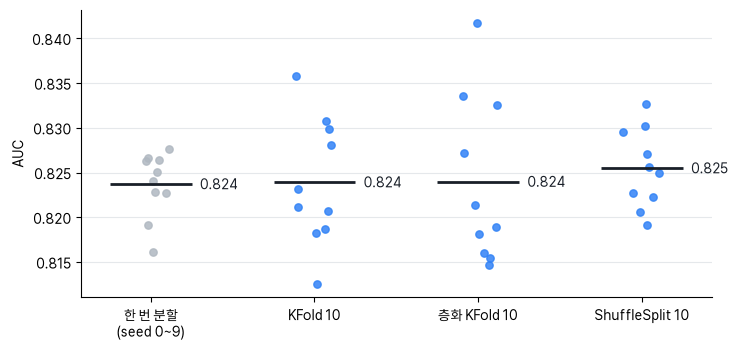

In [12]:
# 그림: 방법별로 나온 AUC 값들의 흩어짐
fig, ax = pyplot.subplots(figsize=(7.5, 3.6))
groups = [('한 번 분할\n(seed 0~9)', split_auc, GRAY), ('KFold 10', auc, BLUE),
          ('층화 KFold 10', sauc, BLUE), ('ShuffleSplit 10', shauc, BLUE)]
rng = numpy.random.RandomState(0)
for i, (lab, vals, col) in enumerate(groups):
    ax.scatter(i + rng.uniform(-0.12, 0.12, len(vals)), vals, color=col, s=28, alpha=0.85, zorder=3)
    ax.hlines(numpy.mean(vals), i - 0.25, i + 0.25, color=INK, lw=2, zorder=4)
    ax.text(i + 0.3, numpy.mean(vals), f'{numpy.mean(vals):.3f}', va='center', fontsize=10, color=INK)
ax.set_xticks(range(len(groups))); ax.set_xticklabels([g[0] for g in groups], fontsize=10)
ax.set_ylabel('AUC'); ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', color='#E5E8EB'); ax.set_axisbelow(True)
pyplot.tight_layout(); pyplot.savefig('../figures/lab3_resampling.png', dpi=200); pyplot.show()

## 정리: 발견 → 다음 질문

- 발견 1: **방법마다 고른 변수가 달랐다.** 카이제곱은 값이 큰 열(소득)을, 트리 중요도는 범위가 넓은 열을 우대한다. 여러 방법에서 공통으로 뽑힌 것은 defaulted, revol, age, late30.
- 발견 2: **변수를 줄여도 이득이 없었다.** 6개 0.826 vs 8개 0.824, 차이 0.002 < 흔들림 0.007 → 8개 유지.
- 발견 3: **한 번 나눈 시험은 0.816~0.828로 흔들린다.** 10-fold는 0.824 ± 0.007. LOOCV는 약 7.7시간이고 AUC를 못 낸다.

**목표(연체 예측)에 대한 결론:** 이후 모든 비교는 **층화 10-fold AUC**로 통일하고, 변수는 8개를 모두 쓴다.

**다음 질문 (Lab 4):** 그럼 어떤 알고리즘이 연체자를 가장 잘 골라낼까? 정확도 말고 어떤 지표로 볼까?